In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# from notebook import data_inspection


In [2]:
df=pd.read_csv(r"C:\Users\MSII\OneDrive\Desktop\employee-attrition-prediction\data\dataset.csv")


In [3]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [4]:
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

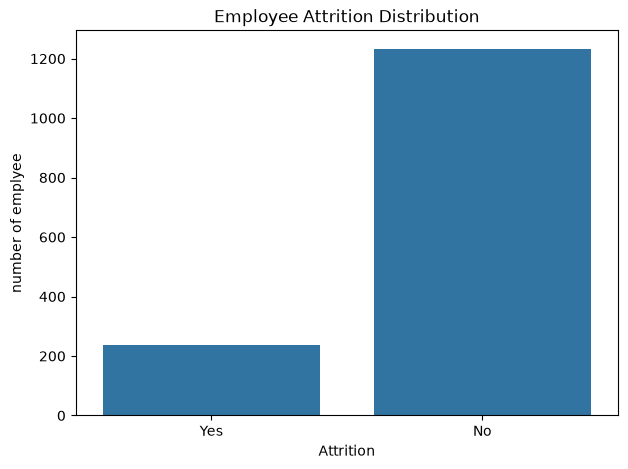

In [6]:
# bar chart
plt.figure(figsize=(7,5))

sns.countplot(data=df,x='Attrition')

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("number of emplyee")
plt.show()

check age Distrubution

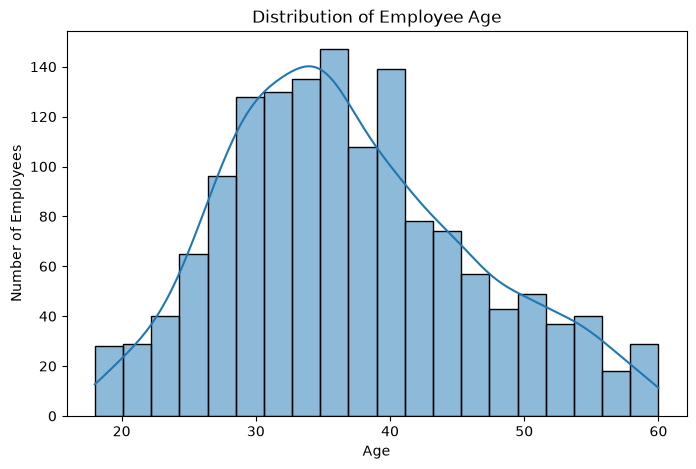

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Employee Age")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

Monthly Income analysis

<function matplotlib.pyplot.show(close=None, block=None)>

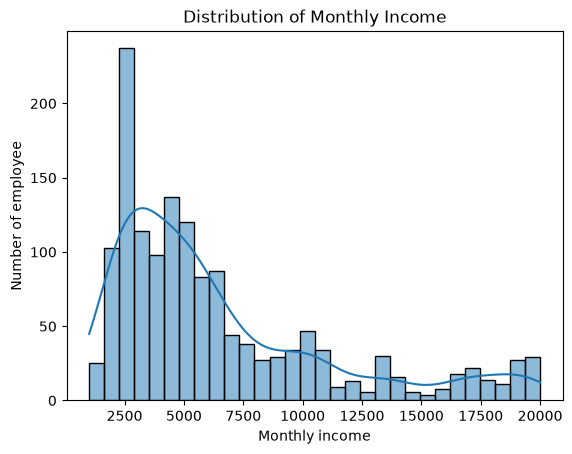

In [8]:
plt.Figure(figsize=(5,5))
sns.histplot(data=df, x="MonthlyIncome", bins=30, kde=True)
plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly income")
plt.ylabel("Number of employee")
plt.show

Working Experince

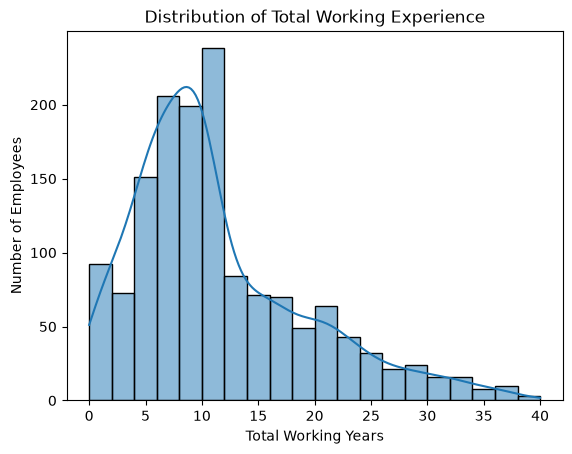

In [9]:
plt.Figure(figsize=(5,5))
sns.histplot(data=df,x="TotalWorkingYears", bins=20, kde=True)

plt.title("Distribution of Total Working Experience")
plt.xlabel("Total Working Years")
plt.ylabel("Number of Employees")

plt.show()

Categrical features analysis

Overtime distribution

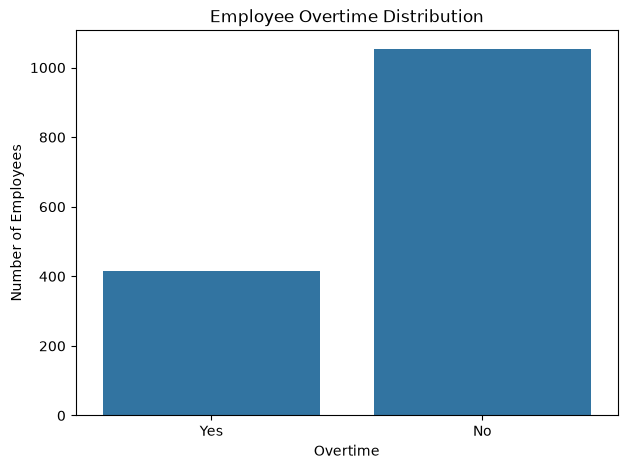

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="OverTime")

plt.title("Employee Overtime Distribution")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.show()

Department Distribution

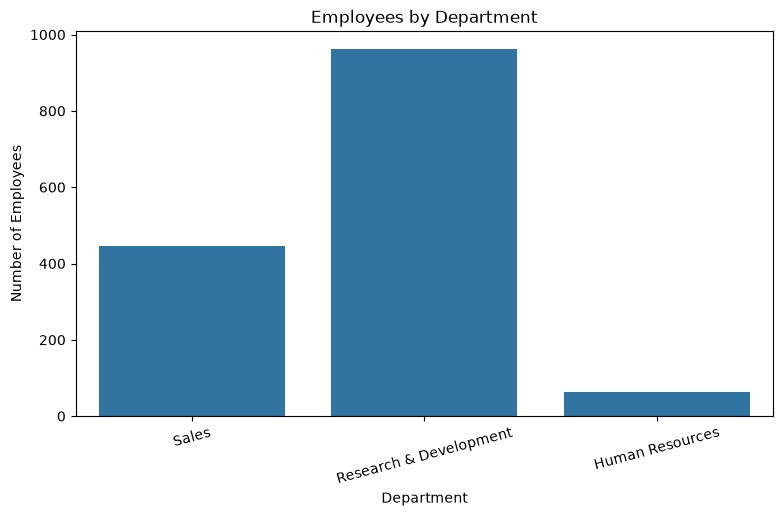

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Department")

plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)

plt.show()

Job Role Distribution

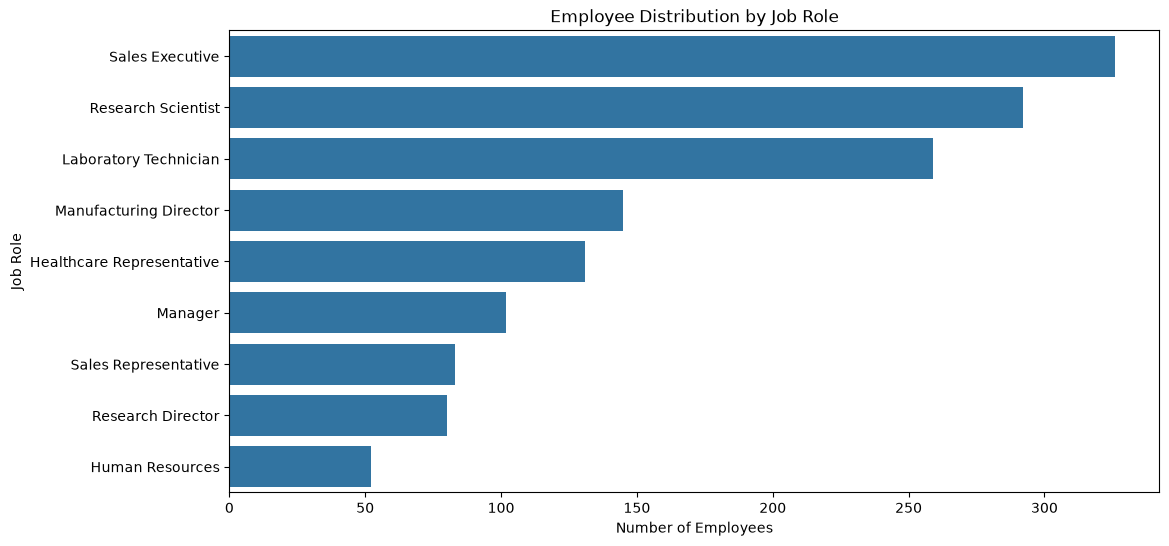

In [12]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, y="JobRole")

plt.title("Employee Distribution by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

plt.show()

Comparing attrition using boxplot

Age vs Attrition

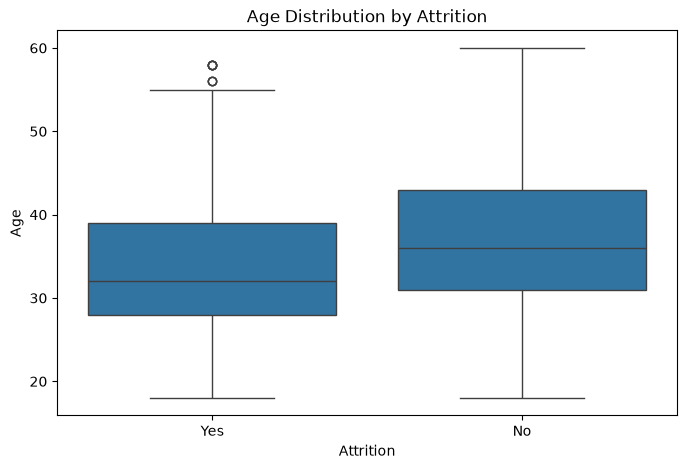

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="Age")

plt.title("Age Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

plt.show()

Monthly Income vs Attrition

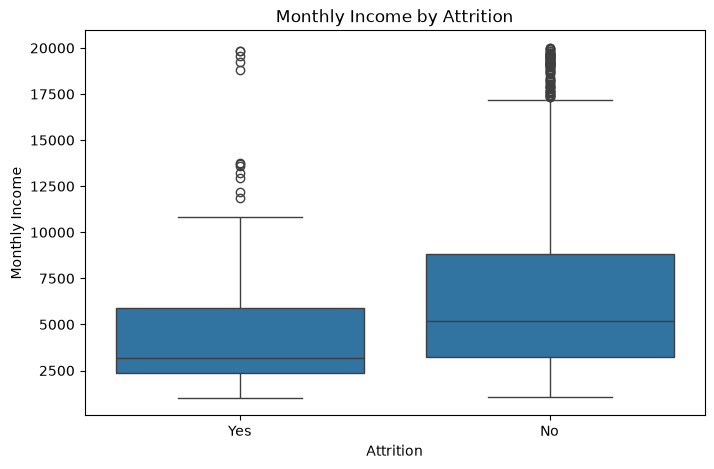

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")

plt.title("Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

Years at Company vs Attrition

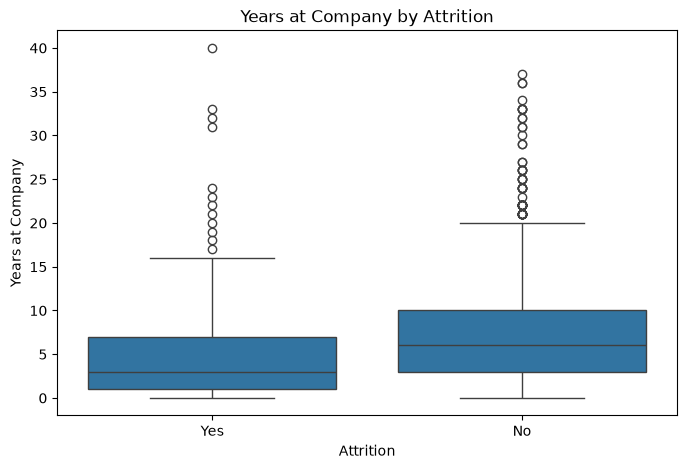

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="YearsAtCompany")

plt.title("Years at Company by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

Attrition Rate Analysis

In [ ]:
def plot_attrition_rate(column):
    attrition_rate = (
        df.assign(
            attrition_flag=(df["Attrition"] == "Yes").astype(int)
        )
        .groupby(column)["attrition_flag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=attrition_rate.index.astype(str),
        y=attrition_rate.values
    )

    plt.title(f"Attrition Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Attrition Rate (%)")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    return attrition_rate

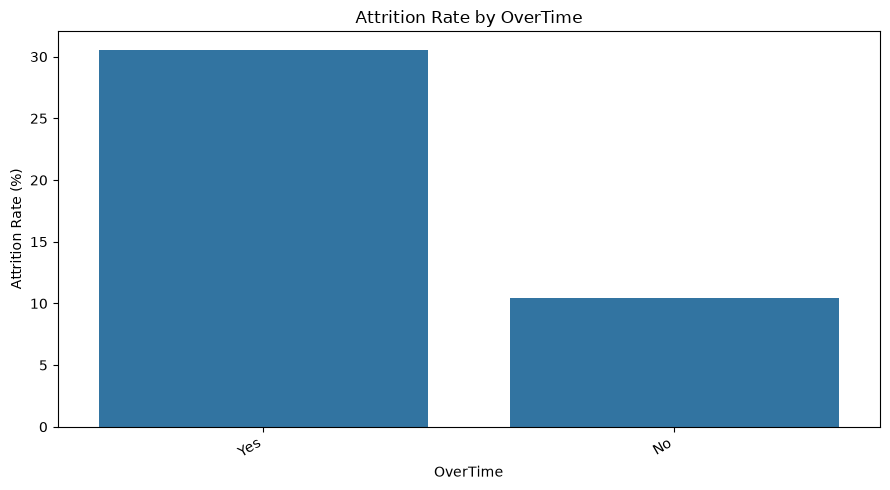

None


In [20]:
overtime_rate = plot_attrition_rate("OverTime")

print(overtime_rate)
# .groupby(column)["attrition_flag"].mean()

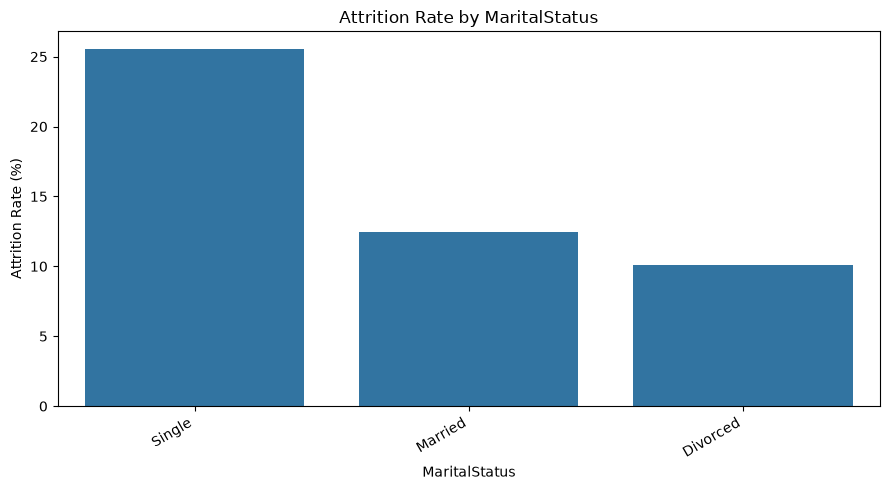

None


In [21]:
marital_rate = plot_attrition_rate("MaritalStatus")

print(marital_rate)

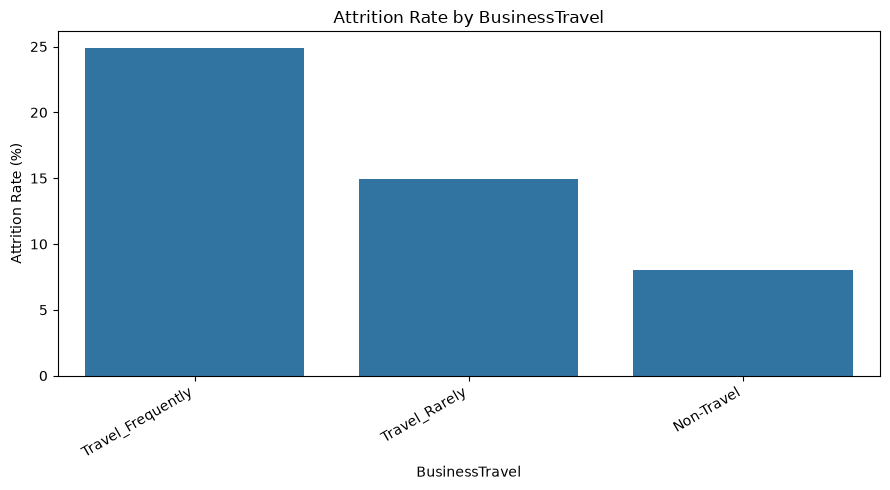

None


In [22]:
travel_rate = plot_attrition_rate("BusinessTravel")

print(travel_rate)

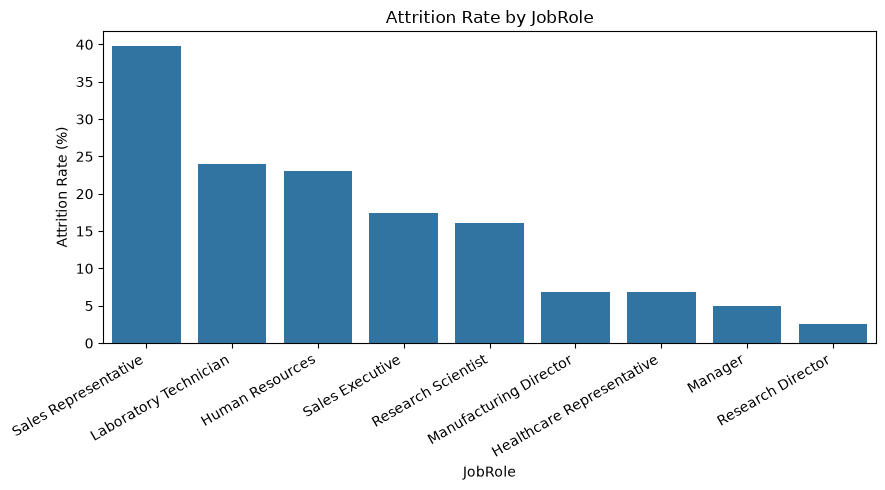

None


In [23]:
jobrole_rate = plot_attrition_rate("JobRole")

print(jobrole_rate)

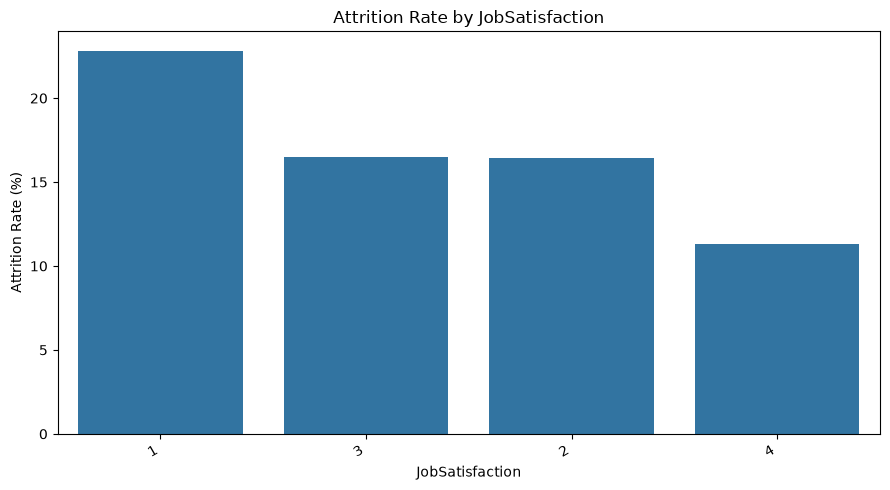

None


In [24]:
satisfaction_rate = plot_attrition_rate("JobSatisfaction")

print(satisfaction_rate)

Correlation Analysis

In [25]:
eda_df = df.copy()

eda_df["AttritionFlag"] = eda_df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

In [26]:
# select numeric column
numeric_df = eda_df.select_dtypes(include="number")

In [27]:
columns_to_exclude = [
    "EmployeeNumber",
    "EmployeeCount",
    "StandardHours"
]

numeric_df = numeric_df.drop(
    columns=columns_to_exclude,
    errors="ignore"
)

In [28]:
correlation_matrix = numeric_df.corr()

correlation_matrix["AttritionFlag"].sort_values(
    ascending=False
)

AttritionFlag               1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
Name: AttritionFlag, dtype: float64

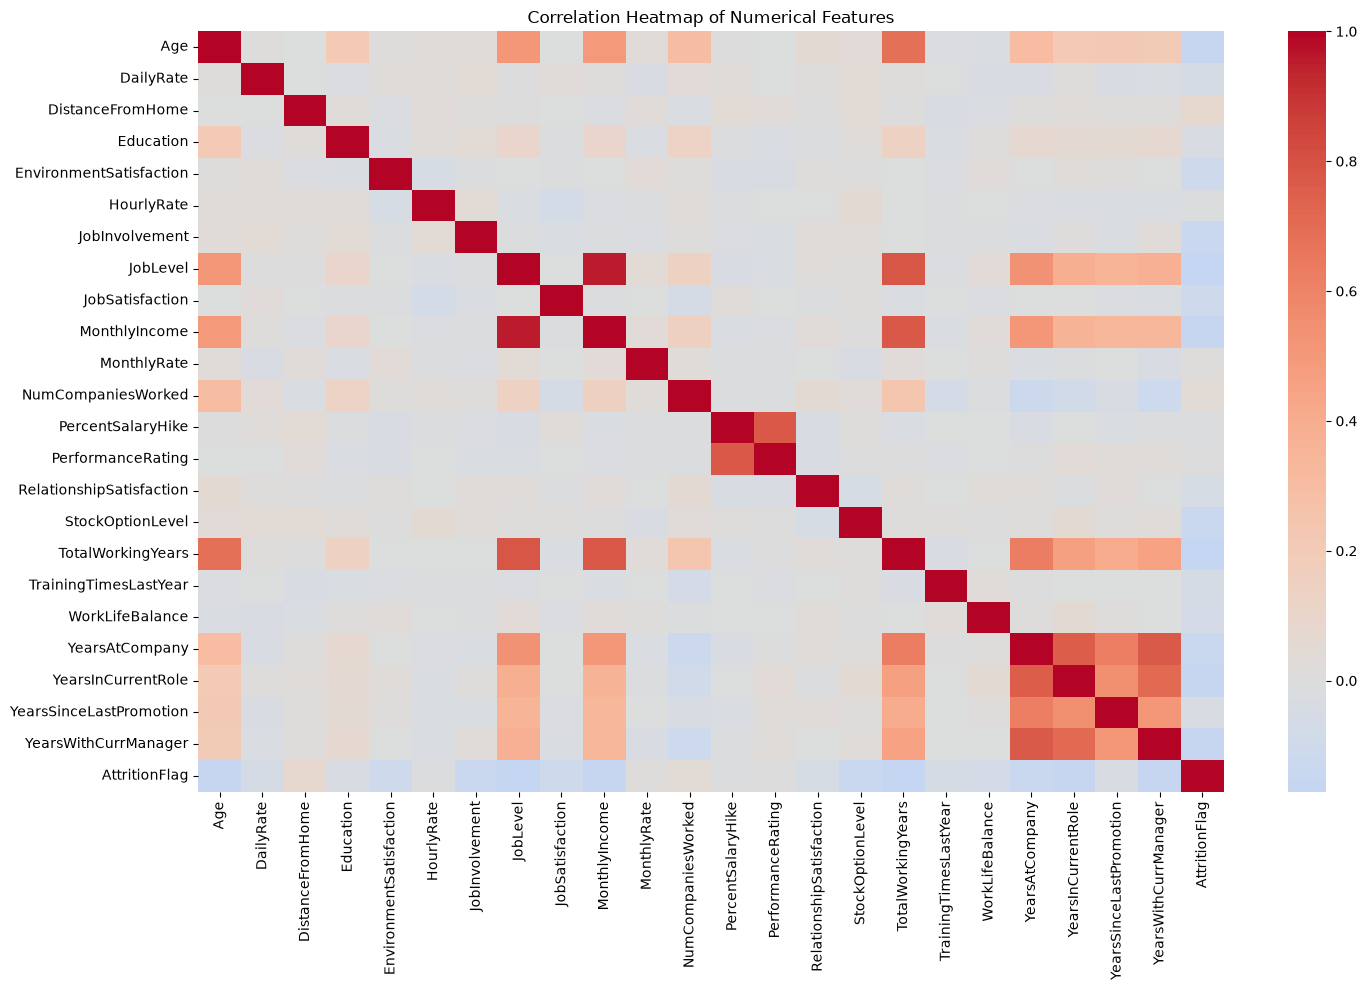

In [29]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.show()

# EDA Findings

## 1. Target Distribution
- Attrition Yes aur No ka count:
- Class imbalance observed:

## 2. Numerical Features
- Age distribution:
- Monthly Income distribution:
- Total Working Years distribution:

## 3. Categorical Features
- Overtime distribution:
- Department distribution:
- Job Role distribution:

## 4. Attrition Rate Analysis
- Attrition rate by Overtime:
- Attrition rate by Job Role:
- Attrition rate by Job Satisfaction:
- Attrition rate by Business Travel:

## 5. Correlation Analysis
- Numerical features with noticeable correlations:
- Correlation with AttritionFlag:

## 6. Key Observations
- Observation 1:
- Observation 2:
- Observation 3: